# MuleGuard.AI — Exploratory Data Analysis

**Dataset:** IBM AML (HI-Small variant)  
**Source:** Cleaned by `scripts/data_prep.py` → `ml/data/processed/transactions_clean.parquet`  

This notebook performs a comprehensive EDA covering:
1. Dataset overview and data quality audit
2. Class imbalance analysis (legitimate vs laundering)
3. Currency distribution (payment and receiving)
4. Temporal patterns (hourly, daily)
5. Amount distribution (overall and by class)
6. Cross-currency transaction analysis
7. Top accounts by transaction volume
8. Summary and implications for model training

---
## 1. Setup and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

COLORS = {
    "legitimate": "#2ecc71",
    "laundering": "#e74c3c",
    "primary": "#3498db",
    "secondary": "#9b59b6",
}

df = pd.read_parquet("../data/processed/transactions_clean.parquet")
print(f"Dataset loaded: {len(df):,} rows x {len(df.columns)} columns")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

Dataset loaded: 5,078,345 rows x 11 columns
Memory usage: 1896.5 MB


---
## 2. Dataset Overview and Data Quality Audit

In [2]:
print("=" * 60)
print("              DATASET OVERVIEW")
print("=" * 60)
print(f"\nTotal Transactions : {len(df):>12,}")
print(f"Columns            : {len(df.columns):>12}")
print(f"Date Range         : {df['timestamp'].min()} → {df['timestamp'].max()}")
print(f"Unique From Accts  : {df['from_account'].nunique():>12,}")
print(f"Unique To Accts    : {df['to_account'].nunique():>12,}")
print(f"Unique Banks (From): {df['from_bank'].nunique():>12,}")
print(f"Unique Banks (To)  : {df['to_bank'].nunique():>12,}")
print(f"Payment Formats    : {df['payment_format'].nunique():>12,}")
print(f"Payment Currencies : {df['payment_currency'].nunique():>12,}")

print("\n" + "=" * 60)
print("              DATA QUALITY CHECKS")
print("=" * 60)

null_counts = df.isnull().sum()
has_nulls = null_counts[null_counts > 0]
print(f"\nNull values         : {len(has_nulls)} columns with nulls" if len(has_nulls) > 0 else "\nNull values         : NONE ✓")
if len(has_nulls) > 0:
    print(has_nulls)

neg_paid = (df["amount_paid"] < 0).sum()
neg_recv = (df["amount_received"] < 0).sum()
print(f"Negative amounts    : paid={neg_paid}, received={neg_recv}" + (" ✓" if neg_paid == 0 and neg_recv == 0 else " ⚠"))

is_sorted = df["timestamp"].is_monotonic_increasing
print(f"Chronological order : {'YES ✓' if is_sorted else 'NO ⚠'}")

print(f"Timestamp timezone  : {df['timestamp'].dt.tz}")

              DATASET OVERVIEW

Total Transactions :    5,078,345
Columns            :           11
Date Range         : 2022-09-01 00:00:00+00:00 → 2022-09-18 16:18:00+00:00
Unique From Accts  :      496,995
Unique To Accts    :      420,636
Unique Banks (From):       30,470
Unique Banks (To)  :       15,811
Payment Formats    :            7
Payment Currencies :           15

              DATA QUALITY CHECKS

Null values         : NONE ✓
Negative amounts    : paid=0, received=0 ✓
Chronological order : YES ✓
Timestamp timezone  : UTC


In [3]:
print("Column Data Types:")
print("-" * 40)
for col in df.columns:
    print(f"  {col:<25} {str(df[col].dtype):<20}")

print("\nFirst 5 rows:")
df.head()

Column Data Types:
----------------------------------------
  timestamp                 datetime64[ns, UTC] 
  from_bank                 int64               
  from_account              object              
  to_bank                   int64               
  to_account                object              
  receiving_currency        object              
  payment_currency          object              
  payment_format            object              
  is_laundering             int64               
  amount_paid               float64             
  amount_received           float64             

First 5 rows:


,timestamp,from_bank,from_account,to_bank,to_account,receiving_currency,payment_currency,payment_format,is_laundering,amount_paid,amount_received
0,2022-09-01 00:00:00+00:00,121,8123FB9B0,121,8123FB9B0,Saudi Riyal,Saudi Riyal,Reinvestment,0,12.8628,12.8628
1,2022-09-01 00:00:00+00:00,25170,8095AF7C0,25170,8095AF7C0,Canadian Dollar,Canadian Dollar,Reinvestment,0,"2,898.8908","2,898.8908"
2,2022-09-01 00:00:00+00:00,25665,809A7D4B0,24779,809189BA0,Canadian Dollar,Canadian Dollar,Credit Card,0,72.1426,72.1426
3,2022-09-01 00:00:00+00:00,32317,800D4E490,12004,800D4E750,Euro,Euro,Wire,0,"13,939.0500","13,939.0500"
4,2022-09-01 00:00:00+00:00,1024,800C8D9D0,1024,800C8D9D0,Euro,Euro,Reinvestment,0,10.3700,10.3700


---
## 3. Class Imbalance Analysis

The `is_laundering` column is our target label. Extreme class imbalance means we **cannot use accuracy** as a metric — a model that predicts 0 for everything would get 99.9% accuracy. We must use **PR-AUC** and **F1-score** instead.

              CLASS DISTRIBUTION

Legitimate (0) :  5,073,168 (99.8981%)
Laundering (1) :      5,177 (0.1019%)
Imbalance Ratio: 1 : 980


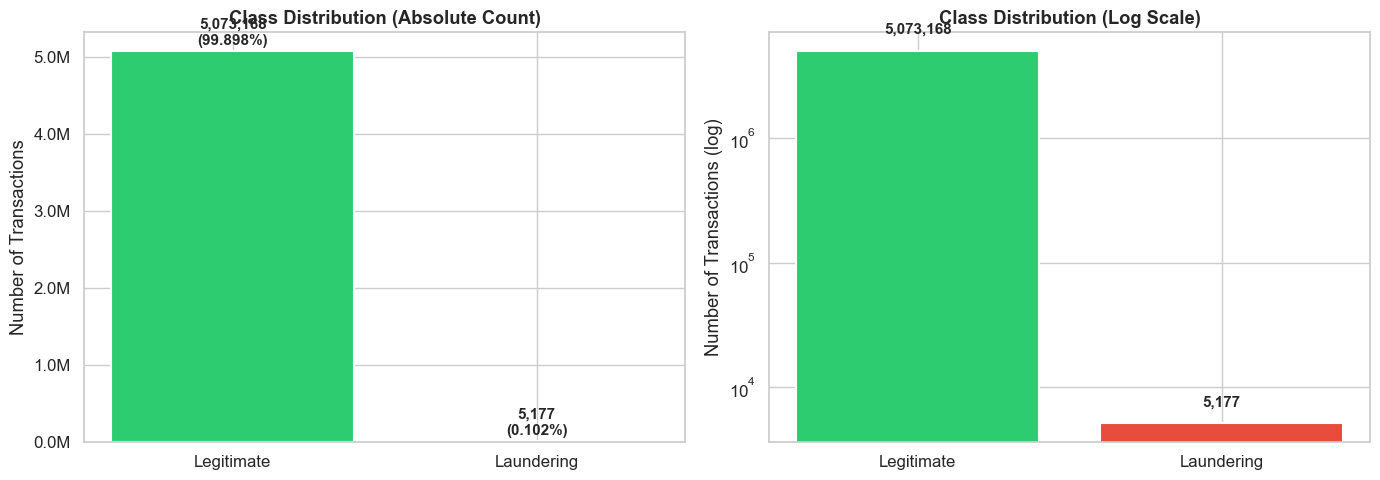


⚠ IMPLICATION: Must use SMOTE/class weights during training.
  Accuracy is a useless metric — use PR-AUC and F1-score.


In [4]:
class_counts = df["is_laundering"].value_counts()
class_pct = df["is_laundering"].value_counts(normalize=True) * 100

print("=" * 60)
print("              CLASS DISTRIBUTION")
print("=" * 60)
print(f"\nLegitimate (0) : {class_counts[0]:>10,} ({class_pct[0]:.4f}%)")
print(f"Laundering (1) : {class_counts[1]:>10,} ({class_pct[1]:.4f}%)")
print(f"Imbalance Ratio: 1 : {class_counts[0] / class_counts[1]:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
bars = axes[0].bar(
    ["Legitimate", "Laundering"],
    class_counts.values,
    color=[COLORS["legitimate"], COLORS["laundering"]],
    edgecolor="white",
    linewidth=1.5,
)
for bar, count, pct in zip(bars, class_counts.values, class_pct.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + len(df) * 0.01,
        f"{count:,}\n({pct:.3f}%)",
        ha="center", va="bottom", fontweight="bold", fontsize=11,
    )
axes[0].set_title("Class Distribution (Absolute Count)", fontweight="bold")
axes[0].set_ylabel("Number of Transactions")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))

# Log-scale bar to show the minority class is not zero
axes[1].bar(
    ["Legitimate", "Laundering"],
    class_counts.values,
    color=[COLORS["legitimate"], COLORS["laundering"]],
    edgecolor="white",
    linewidth=1.5,
)
axes[1].set_yscale("log")
axes[1].set_title("Class Distribution (Log Scale)", fontweight="bold")
axes[1].set_ylabel("Number of Transactions (log)")
for bar, count in zip(axes[1].patches, class_counts.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() * 1.3,
        f"{count:,}",
        ha="center", va="bottom", fontweight="bold", fontsize=11,
    )

plt.tight_layout()
plt.savefig("../results/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n⚠ IMPLICATION: Must use SMOTE/class weights during training.")
print("  Accuracy is a useless metric — use PR-AUC and F1-score.")

---
## 4. Currency Distribution

The dataset contains multi-currency transactions. All amounts have been normalized to USD in `data_prep.py`. The original currency columns are preserved for categorical feature use.

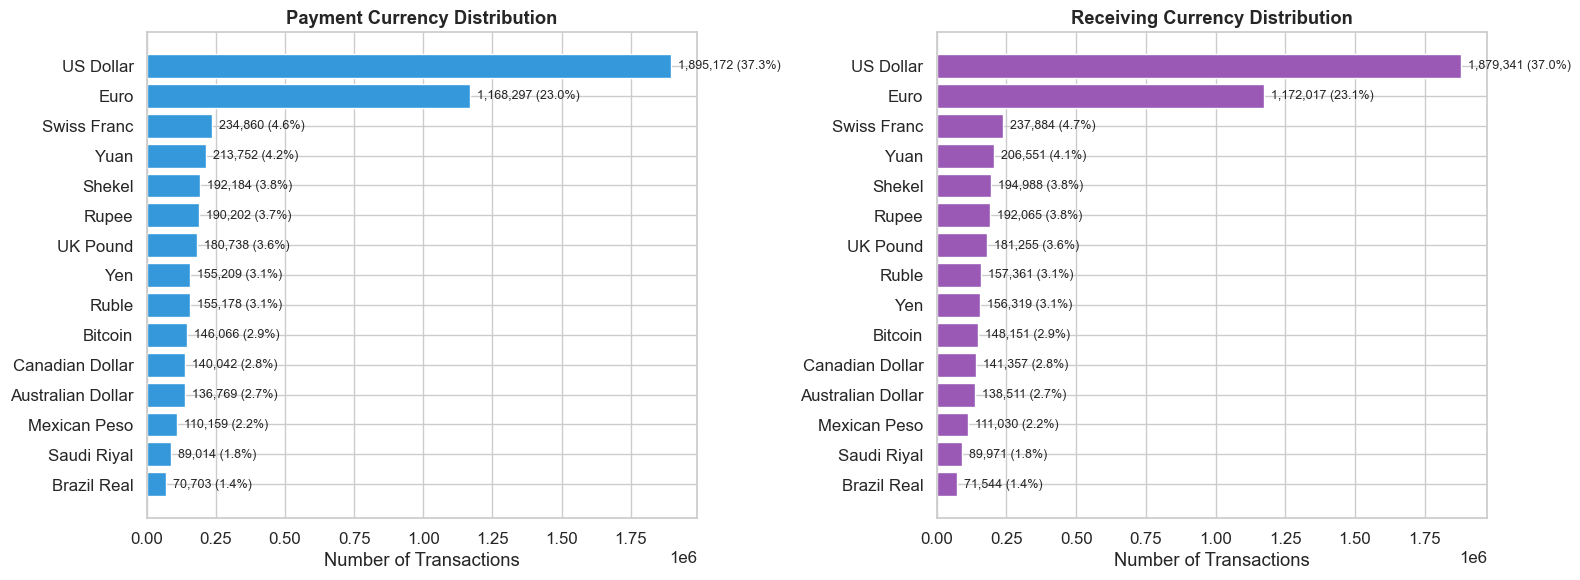


Cross-currency transactions: 72,170 (1.42%)
Same-currency transactions : 5,006,175 (98.58%)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Payment Currency
pay_counts = df["payment_currency"].value_counts()
axes[0].barh(pay_counts.index[::-1], pay_counts.values[::-1], color=COLORS["primary"], edgecolor="white")
axes[0].set_title("Payment Currency Distribution", fontweight="bold")
axes[0].set_xlabel("Number of Transactions")
for i, (val, name) in enumerate(zip(pay_counts.values[::-1], pay_counts.index[::-1])):
    axes[0].text(val + len(df) * 0.005, i, f"{val:,} ({val/len(df)*100:.1f}%)", va="center", fontsize=9)

# Receiving Currency
recv_counts = df["receiving_currency"].value_counts()
axes[1].barh(recv_counts.index[::-1], recv_counts.values[::-1], color=COLORS["secondary"], edgecolor="white")
axes[1].set_title("Receiving Currency Distribution", fontweight="bold")
axes[1].set_xlabel("Number of Transactions")
for i, (val, name) in enumerate(zip(recv_counts.values[::-1], recv_counts.index[::-1])):
    axes[1].text(val + len(df) * 0.005, i, f"{val:,} ({val/len(df)*100:.1f}%)", va="center", fontsize=9)

plt.tight_layout()
plt.savefig("../results/currency_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Cross-currency transactions
cross_currency = (df["payment_currency"] != df["receiving_currency"]).sum()
print(f"\nCross-currency transactions: {cross_currency:,} ({cross_currency/len(df)*100:.2f}%)")
print(f"Same-currency transactions : {len(df) - cross_currency:,} ({(len(df)-cross_currency)/len(df)*100:.2f}%)")

    CROSS-CURRENCY vs LAUNDERING RATE
                laundering_count  total_count  laundering_rate
Same Currency               5177      5006175           0.0010
Cross Currency                 0        72170           0.0000


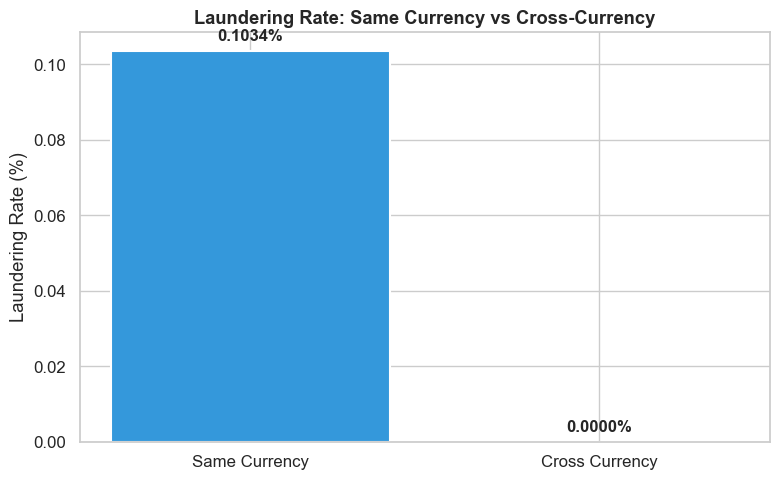

In [6]:
# Cross-currency vs laundering rate
df["is_cross_currency"] = (df["payment_currency"] != df["receiving_currency"]).astype(int)

cross_stats = df.groupby("is_cross_currency")["is_laundering"].agg(["sum", "count", "mean"])
cross_stats.columns = ["laundering_count", "total_count", "laundering_rate"]
cross_stats.index = ["Same Currency", "Cross Currency"]

print("=" * 60)
print("    CROSS-CURRENCY vs LAUNDERING RATE")
print("=" * 60)
print(cross_stats.to_string())

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    cross_stats.index,
    cross_stats["laundering_rate"] * 100,
    color=[COLORS["primary"], COLORS["laundering"]],
    edgecolor="white",
    linewidth=1.5,
)
for bar, rate in zip(bars, cross_stats["laundering_rate"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.002,
        f"{rate*100:.4f}%",
        ha="center", va="bottom", fontweight="bold", fontsize=12,
    )
ax.set_title("Laundering Rate: Same Currency vs Cross-Currency", fontweight="bold")
ax.set_ylabel("Laundering Rate (%)")
plt.tight_layout()
plt.savefig("../results/cross_currency_laundering.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 5. Temporal Patterns

Mule transactions often exhibit temporal patterns — activity bursts during off-hours (late night) or specific days. This analysis reveals whether time-of-day and day-of-week are discriminative features.

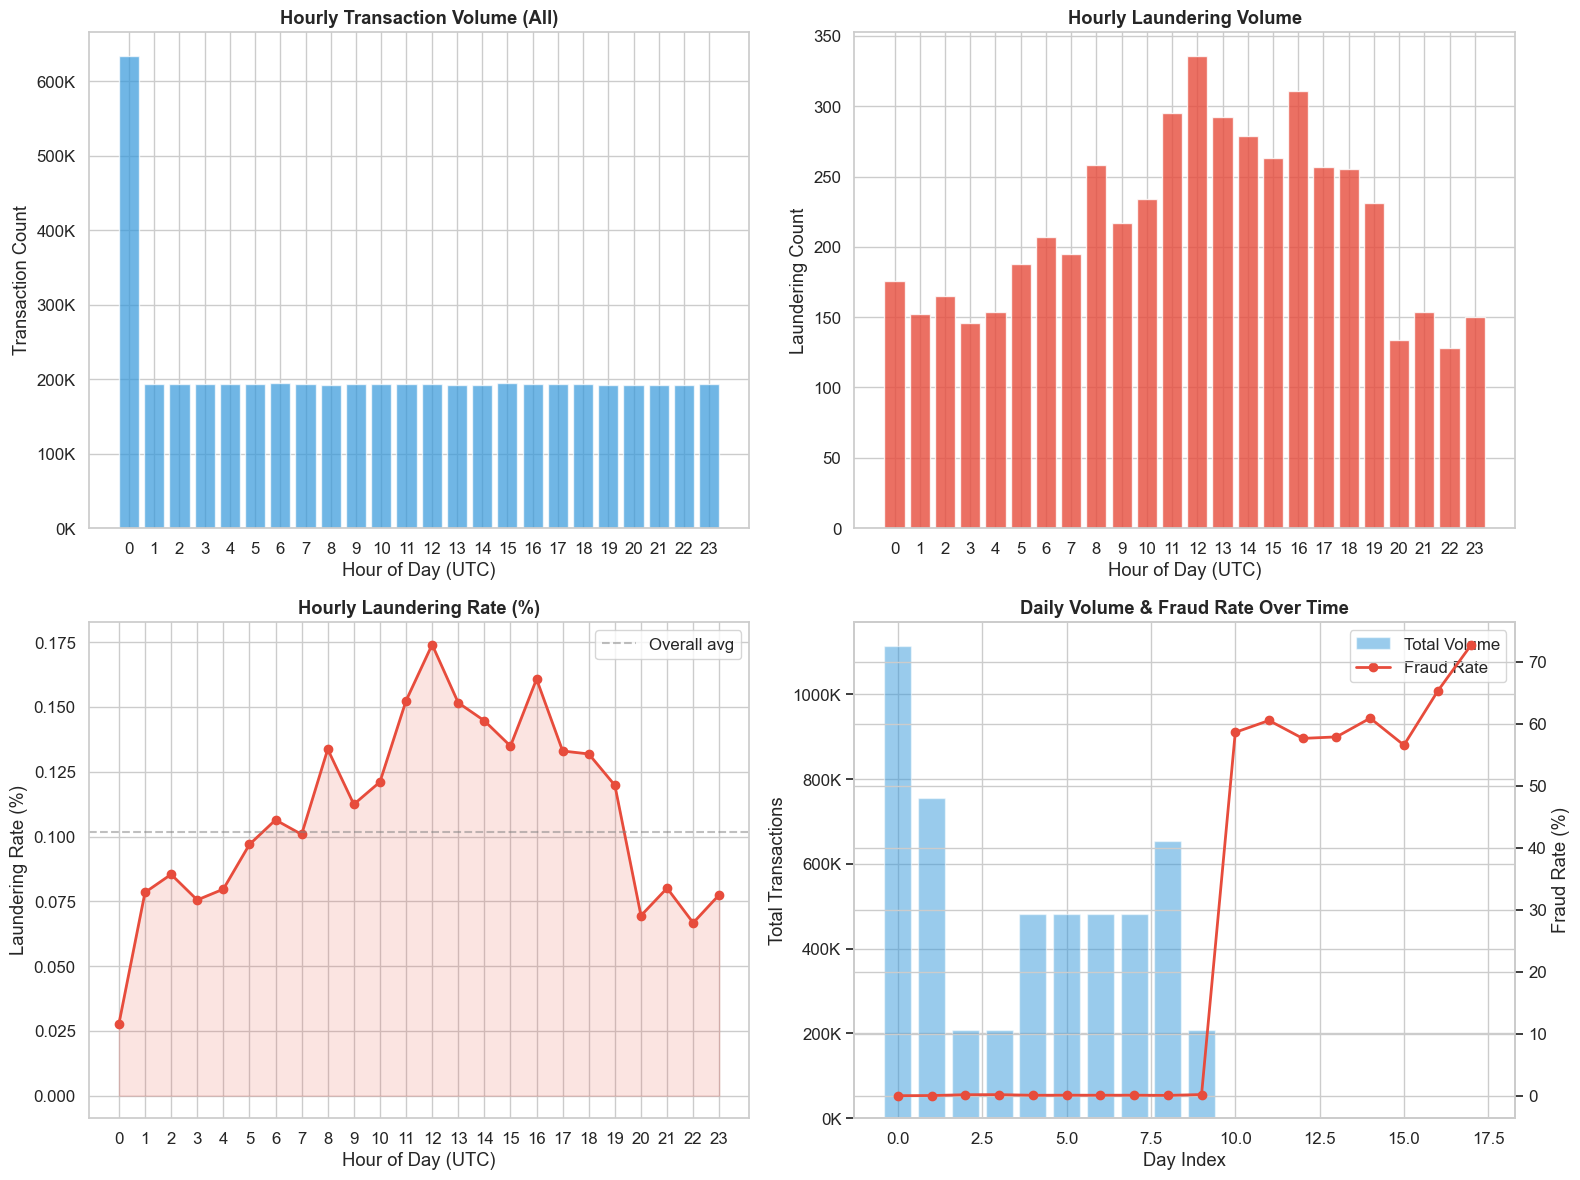

In [7]:
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.day_name()
df["date"] = df["timestamp"].dt.date

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- Panel 1: Hourly transaction volume ---
hourly_all = df.groupby("hour").size()
hourly_fraud = df[df["is_laundering"] == 1].groupby("hour").size()

axes[0, 0].bar(hourly_all.index, hourly_all.values, color=COLORS["primary"], alpha=0.7, label="All Transactions")
axes[0, 0].set_title("Hourly Transaction Volume (All)", fontweight="bold")
axes[0, 0].set_xlabel("Hour of Day (UTC)")
axes[0, 0].set_ylabel("Transaction Count")
axes[0, 0].set_xticks(range(0, 24))
axes[0, 0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))

# --- Panel 2: Hourly laundering volume ---
axes[0, 1].bar(hourly_fraud.index, hourly_fraud.values, color=COLORS["laundering"], alpha=0.8, label="Laundering")
axes[0, 1].set_title("Hourly Laundering Volume", fontweight="bold")
axes[0, 1].set_xlabel("Hour of Day (UTC)")
axes[0, 1].set_ylabel("Laundering Count")
axes[0, 1].set_xticks(range(0, 24))

# --- Panel 3: Hourly laundering RATE ---
hourly_rate = (hourly_fraud / hourly_all * 100).fillna(0)
axes[1, 0].plot(hourly_rate.index, hourly_rate.values, marker="o", color=COLORS["laundering"], linewidth=2)
axes[1, 0].fill_between(hourly_rate.index, hourly_rate.values, alpha=0.15, color=COLORS["laundering"])
axes[1, 0].set_title("Hourly Laundering Rate (%)", fontweight="bold")
axes[1, 0].set_xlabel("Hour of Day (UTC)")
axes[1, 0].set_ylabel("Laundering Rate (%)")
axes[1, 0].set_xticks(range(0, 24))
axes[1, 0].axhline(y=df["is_laundering"].mean() * 100, color="gray", linestyle="--", alpha=0.5, label="Overall avg")
axes[1, 0].legend()

# --- Panel 4: Daily volume over time ---
daily_counts = df.groupby("date").agg(
    total=("is_laundering", "count"),
    fraud=("is_laundering", "sum"),
)
daily_counts["rate"] = daily_counts["fraud"] / daily_counts["total"] * 100

ax2 = axes[1, 1].twinx()
axes[1, 1].bar(range(len(daily_counts)), daily_counts["total"].values, color=COLORS["primary"], alpha=0.5, label="Total Volume")
ax2.plot(range(len(daily_counts)), daily_counts["rate"].values, color=COLORS["laundering"], marker="o", linewidth=2, label="Fraud Rate")
axes[1, 1].set_title("Daily Volume & Fraud Rate Over Time", fontweight="bold")
axes[1, 1].set_xlabel("Day Index")
axes[1, 1].set_ylabel("Total Transactions")
ax2.set_ylabel("Fraud Rate (%)")
axes[1, 1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
lines1, labels1 = axes[1, 1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[1, 1].legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.tight_layout()
plt.savefig("../results/temporal_patterns.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# Day-of-week analysis
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_stats = df.groupby("day_of_week").agg(
    total=("is_laundering", "count"),
    fraud=("is_laundering", "sum"),
).reindex(day_order)
dow_stats["rate"] = dow_stats["fraud"] / dow_stats["total"] * 100

print("Day-of-Week Breakdown:")
print("-" * 55)
print(f"{'Day':<12} {'Total':>12} {'Laundering':>12} {'Rate':>10}")
print("-" * 55)
for day, row in dow_stats.iterrows():
    print(f"{day:<12} {row['total']:>12,.0f} {row['fraud']:>12,.0f} {row['rate']:>9.4f}%")
print("-" * 55)

Day-of-Week Breakdown:
-------------------------------------------------------
Day                 Total   Laundering       Rate
-------------------------------------------------------
Monday            482,931          641    0.1327%
Tuesday           482,273          637    0.1321%
Wednesday         482,872          567    0.1174%
Thursday        1,597,740          889    0.0556%
Friday          1,408,962          948    0.0673%
Saturday          415,730          848    0.2040%
Sunday            207,837          647    0.3113%
-------------------------------------------------------


---
## 6. Amount Distribution

Financial data is typically heavy-tailed (most transactions are small, a few are very large). Log-scale visualization is essential to see the full distribution.

In [9]:
print("=" * 60)
print("         AMOUNT STATISTICS (USD-Normalized)")
print("=" * 60)

for label, subset in [("All Transactions", df), ("Legitimate Only", df[df["is_laundering"]==0]), ("Laundering Only", df[df["is_laundering"]==1])]:
    print(f"\n--- {label} ---")
    stats = subset["amount_paid"].describe()
    print(f"  Count  : {stats['count']:>14,.0f}")
    print(f"  Mean   : ${stats['mean']:>14,.2f}")
    print(f"  Median : ${stats['50%']:>14,.2f}")
    print(f"  Std    : ${stats['std']:>14,.2f}")
    print(f"  Min    : ${stats['min']:>14,.2f}")
    print(f"  Max    : ${stats['max']:>14,.2f}")

         AMOUNT STATISTICS (USD-Normalized)

--- All Transactions ---
  Count  :      5,078,345
  Mean   : $    340,785.34
  Median : $        855.83
  Std    : $ 24,214,035.10
  Min    : $          0.00
  Max    : $28,493,009,546.48

--- Legitimate Only ---
  Count  :      5,073,168
  Mean   : $    336,002.83
  Median : $        853.38
  Std    : $ 23,126,956.46
  Min    : $          0.00
  Max    : $28,493,009,546.48

--- Laundering Only ---
  Count  :          5,177
  Mean   : $  5,027,375.85
  Median : $      5,621.88
  Std    : $225,843,719.59
  Min    : $          0.33
  Max    : $15,910,512,195.71


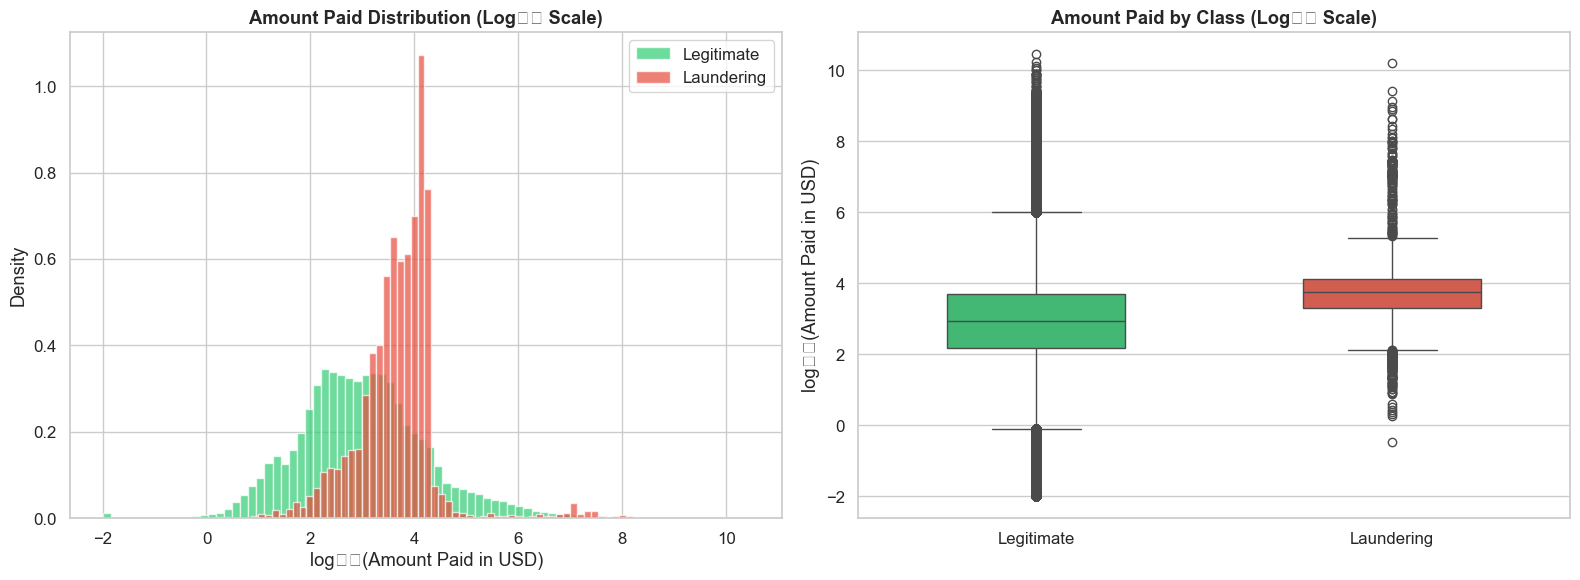

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Log-scale histogram for paid amounts
legit_amounts = df[df["is_laundering"] == 0]["amount_paid"].clip(lower=0.01)
fraud_amounts = df[df["is_laundering"] == 1]["amount_paid"].clip(lower=0.01)

axes[0].hist(np.log10(legit_amounts), bins=80, alpha=0.7, color=COLORS["legitimate"], label="Legitimate", density=True)
axes[0].hist(np.log10(fraud_amounts), bins=80, alpha=0.7, color=COLORS["laundering"], label="Laundering", density=True)
axes[0].set_title("Amount Paid Distribution (Log₁₀ Scale)", fontweight="bold")
axes[0].set_xlabel("log₁₀(Amount Paid in USD)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Box plot comparison
plot_df = df[["amount_paid", "is_laundering"]].copy()
plot_df["label"] = plot_df["is_laundering"].map({0: "Legitimate", 1: "Laundering"})
plot_df["log_amount"] = np.log10(plot_df["amount_paid"].clip(lower=0.01))

sns.boxplot(
    data=plot_df, x="label", y="log_amount", ax=axes[1],
    palette={"Legitimate": COLORS["legitimate"], "Laundering": COLORS["laundering"]},
    width=0.5,
)
axes[1].set_title("Amount Paid by Class (Log₁₀ Scale)", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("log₁₀(Amount Paid in USD)")

plt.tight_layout()
plt.savefig("../results/amount_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 7. Payment Format Analysis

Payment Format Breakdown:
-------------------------------------------------------
Format                  Total   Laundering       Rate
-------------------------------------------------------
Cheque              1,864,331          324    0.0174%
Credit Card         1,323,324          206    0.0156%
ACH                   600,797        4,483    0.7462%
Cash                  490,891          108    0.0220%
Reinvestment          481,056            0    0.0000%
Wire                  171,855            0    0.0000%
Bitcoin               146,091           56    0.0383%
-------------------------------------------------------


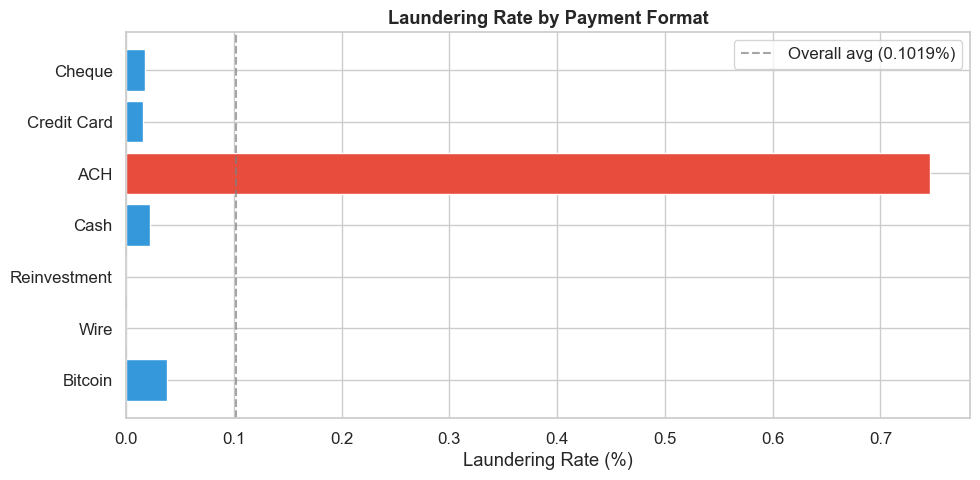

In [11]:
fmt_stats = df.groupby("payment_format").agg(
    total=("is_laundering", "count"),
    fraud=("is_laundering", "sum"),
).sort_values("total", ascending=False)
fmt_stats["rate"] = fmt_stats["fraud"] / fmt_stats["total"] * 100

print("Payment Format Breakdown:")
print("-" * 55)
print(f"{'Format':<18} {'Total':>10} {'Laundering':>12} {'Rate':>10}")
print("-" * 55)
for fmt, row in fmt_stats.iterrows():
    print(f"{fmt:<18} {row['total']:>10,.0f} {row['fraud']:>12,.0f} {row['rate']:>9.4f}%")
print("-" * 55)

fig, ax = plt.subplots(figsize=(10, 5))
bar_colors = [COLORS["laundering"] if r > df["is_laundering"].mean() * 100 else COLORS["primary"] for r in fmt_stats["rate"]]
bars = ax.barh(fmt_stats.index[::-1], fmt_stats["rate"].values[::-1], color=bar_colors[::-1], edgecolor="white")
ax.axvline(x=df["is_laundering"].mean() * 100, color="gray", linestyle="--", alpha=0.7, label=f"Overall avg ({df['is_laundering'].mean()*100:.4f}%)")
ax.set_title("Laundering Rate by Payment Format", fontweight="bold")
ax.set_xlabel("Laundering Rate (%)")
ax.legend()
plt.tight_layout()
plt.savefig("../results/payment_format_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 8. Top Accounts by Volume

Mule accounts often appear as high-volume relay nodes — receiving from many sources and forwarding quickly. Identifying accounts with disproportionately high transaction counts is a key detection signal.

In [12]:
# Top senders
top_senders = df.groupby("from_account").agg(
    txn_count=("is_laundering", "count"),
    fraud_count=("is_laundering", "sum"),
    total_sent=("amount_paid", "sum"),
).sort_values("txn_count", ascending=False).head(15)
top_senders["fraud_rate"] = top_senders["fraud_count"] / top_senders["txn_count"] * 100

print("Top 15 Sender Accounts by Transaction Count:")
print("-" * 75)
print(f"{'Account':<18} {'Txn Count':>10} {'Fraud':>8} {'Rate':>8} {'Total Sent (USD)':>18}")
print("-" * 75)
for acct, row in top_senders.iterrows():
    flag = " ⚠" if row["fraud_rate"] > 1 else ""
    print(f"{str(acct):<18} {row['txn_count']:>10,.0f} {row['fraud_count']:>8,.0f} {row['fraud_rate']:>7.2f}% ${row['total_sent']:>15,.2f}{flag}")

print()

# Top receivers
top_receivers = df.groupby("to_account").agg(
    txn_count=("is_laundering", "count"),
    fraud_count=("is_laundering", "sum"),
    total_received=("amount_received", "sum"),
).sort_values("txn_count", ascending=False).head(15)
top_receivers["fraud_rate"] = top_receivers["fraud_count"] / top_receivers["txn_count"] * 100

print("Top 15 Receiver Accounts by Transaction Count:")
print("-" * 75)
print(f"{'Account':<18} {'Txn Count':>10} {'Fraud':>8} {'Rate':>8} {'Total Recv (USD)':>18}")
print("-" * 75)
for acct, row in top_receivers.iterrows():
    flag = " ⚠" if row["fraud_rate"] > 1 else ""
    print(f"{str(acct):<18} {row['txn_count']:>10,.0f} {row['fraud_count']:>8,.0f} {row['fraud_rate']:>7.2f}% ${row['total_received']:>15,.2f}{flag}")

Top 15 Sender Accounts by Transaction Count:
---------------------------------------------------------------------------
Account             Txn Count    Fraud     Rate   Total Sent (USD)
---------------------------------------------------------------------------
100428660             168,672      243    0.14% $52,762,291,209.75
1004286A8             103,018      158    0.15% $26,069,375,477.37
100428978              20,497       29    0.14% $7,758,072,900.06
1004286F0              18,663       21    0.11% $3,452,030,033.61
100428780              17,264       21    0.12% $4,487,204,389.97
1004289C0              16,794       13    0.08% $3,049,985,140.75
100428810              16,426       26    0.16% $5,772,049,744.27
1004287C8              14,174       16    0.11% $1,617,715,865.90
100428738              13,756       23    0.17% $1,788,595,793.84
100428A51              13,073       18    0.14% $5,125,762,987.96
1004288A0              12,330       16    0.13% $2,065,138,069.25
10042885

---
## 9. Bank-Level Analysis

In [13]:
bank_stats = df.groupby("from_bank").agg(
    total=("is_laundering", "count"),
    fraud=("is_laundering", "sum"),
    avg_amount=("amount_paid", "mean"),
).sort_values("total", ascending=False)
bank_stats["rate"] = bank_stats["fraud"] / bank_stats["total"] * 100

print(f"Total unique sending banks: {len(bank_stats)}")
print(f"\nTop 20 Banks by Transaction Volume:")
print("-" * 70)
print(f"{'Bank':<12} {'Total':>10} {'Laundering':>12} {'Rate':>8} {'Avg Amt (USD)':>15}")
print("-" * 70)
for bank, row in bank_stats.head(20).iterrows():
    print(f"{str(bank):<12} {row['total']:>10,.0f} {row['fraud']:>12,.0f} {row['rate']:>7.3f}% ${row['avg_amount']:>12,.2f}")

Total unique sending banks: 30470

Top 20 Banks by Transaction Volume:
----------------------------------------------------------------------
Bank              Total   Laundering     Rate   Avg Amt (USD)
----------------------------------------------------------------------
70              449,859          633   0.141% $  271,401.03
10               81,629           51   0.062% $  344,106.08
12               79,754           76   0.095% $  203,968.21
1                62,211           50   0.080% $  704,856.06
15               52,511           46   0.088% $  234,959.81
220              52,417           22   0.042% $  376,783.26
20               41,008           67   0.163% $  225,720.34
3                38,413           13   0.034% $  187,604.75
7                31,086           11   0.035% $  299,387.89
211              30,451           26   0.085% $  194,973.82
116              30,232           23   0.076% $  265,481.89
11               29,676           47   0.158% $  257,173.48
22   

---
## 10. Correlation Heatmap

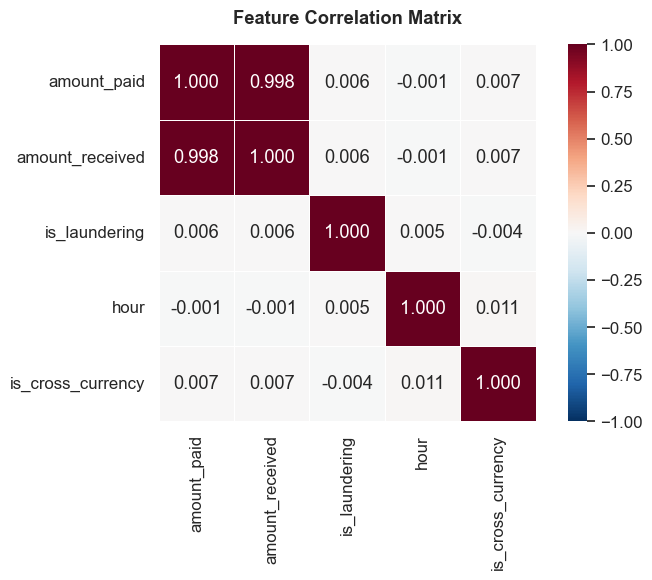


Correlation with is_laundering:
----------------------------------------
  amount_paid              0.0062  ↑
  amount_received          0.0061  ↑
  hour                     0.0055  ↑
  is_cross_currency       -0.0038  ↓


In [14]:
numeric_cols = ["amount_paid", "amount_received", "is_laundering", "hour", "is_cross_currency"]
corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_matrix, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
    square=True, linewidths=0.5, ax=ax,
    vmin=-1, vmax=1,
)
ax.set_title("Feature Correlation Matrix", fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig("../results/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nCorrelation with is_laundering:")
print("-" * 40)
target_corr = corr_matrix["is_laundering"].drop("is_laundering").sort_values(key=abs, ascending=False)
for feat, val in target_corr.items():
    direction = "↑" if val > 0 else "↓"
    print(f"  {feat:<22} {val:>8.4f}  {direction}")

---
## 11. EDA Summary and Model Training Implications

### Key Findings

In [15]:
fraud_count = df["is_laundering"].sum()
legit_count = len(df) - fraud_count

print("=" * 70)
print("                    EDA SUMMARY REPORT")
print("=" * 70)
print(f"""
DATASET PROFILE
  Total Records       : {len(df):>12,}
  Legitimate           : {legit_count:>12,} ({legit_count/len(df)*100:.4f}%)
  Laundering           : {fraud_count:>12,} ({fraud_count/len(df)*100:.4f}%)
  Imbalance Ratio      : 1 : {legit_count // fraud_count}
  Date Range           : {df['timestamp'].min()} → {df['timestamp'].max()}
  Unique Senders       : {df['from_account'].nunique():>12,}
  Unique Receivers     : {df['to_account'].nunique():>12,}
  Payment Currencies   : {df['payment_currency'].nunique():>12}
  Cross-Currency Txns  : {cross_currency:>12,} ({cross_currency/len(df)*100:.2f}%)

MODEL TRAINING IMPLICATIONS
  [1] Class Imbalance   → Use SMOTE / class_weight / is_unbalance in LightGBM
  [2] Metric Choice     → PR-AUC and F1-score (NOT accuracy)
  [3] Amount Features   → Log-transform amounts before feeding to model
  [4] Temporal Features  → Hour-of-day and day-of-week may be weak signals
  [5] Currency Features  → Encode payment_currency as categorical feature
  [6] Graph Potential    → Account-to-account pairs exist for Neo4j graph construction
""")

# Clean up temporary columns
df.drop(columns=["hour", "day_of_week", "date", "is_cross_currency"], inplace=True, errors="ignore")
print("EDA complete. Temporary columns cleaned up.")

                    EDA SUMMARY REPORT

DATASET PROFILE
  Total Records       :    5,078,345
  Legitimate           :    5,073,168 (99.8981%)
  Laundering           :        5,177 (0.1019%)
  Imbalance Ratio      : 1 : 979
  Date Range           : 2022-09-01 00:00:00+00:00 → 2022-09-18 16:18:00+00:00
  Unique Senders       :      496,995
  Unique Receivers     :      420,636
  Payment Currencies   :           15
  Cross-Currency Txns  :       72,170 (1.42%)

MODEL TRAINING IMPLICATIONS
  [1] Class Imbalance   → Use SMOTE / class_weight / is_unbalance in LightGBM
  [2] Metric Choice     → PR-AUC and F1-score (NOT accuracy)
  [3] Amount Features   → Log-transform amounts before feeding to model
  [4] Temporal Features  → Hour-of-day and day-of-week may be weak signals
  [5] Currency Features  → Encode payment_currency as categorical feature
  [6] Graph Potential    → Account-to-account pairs exist for Neo4j graph construction

EDA complete. Temporary columns cleaned up.
